# Nigeria Covid-19: Burden, Concentration and Fatality by State

The analytical companion to `powerbi/nigeria-covid19-dashboard.pbix`. The dashboard reports totals and rankings; this notebook adds
validation, concentration measures, and **fatality rates with confidence intervals**, which are needed to avoid over-reading
small states.

**Data:** a single snapshot of cumulative cases by state (confirmed, active, discharged, deaths), taken from the Nigeria Centre for
Disease Control (NCDC) website by the dashboard's Power Query step and embedded in the `.pbix` (file metadata dates it to about
31 May 2022). Exported to `data/nigeria_covid19_by_state.csv` by `scripts/export_pbix_data.py`.

**Questions**

1. Is the data internally consistent?
2. How concentrated is the burden across states?
3. Which states have a fatality rate that is *genuinely* higher or lower than the national rate, once sample size is accounted for?
4. Where are active cases still concentrated?

## 1. Setup and data loading

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
})
BLUE, GREEN, RED, GREY, ORANGE = "#2b6cb0", "#2f855a", "#c53030", "#a0aec0", "#dd6b20"
MIN_CASES = 1000   # minimum confirmed cases for a state's rate to be interpreted


def wilson(k, n, z=1.96):
    """95% Wilson score interval for a proportion k/n."""
    p = k / n
    denom = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denom
    return centre - half, centre + half

In [2]:
CANDIDATES = [Path("data/nigeria_covid19_by_state.csv"), Path("../data/nigeria_covid19_by_state.csv")]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("nigeria_covid19_by_state.csv not found - run `python scripts/export_pbix_data.py` first.")

df = pd.read_csv(DATA_PATH).rename(columns={
    "Confirmed Cases": "Confirmed", "Active Cases": "Active",
    "Discharged Cases": "Discharged", "Deaths Recorded": "Deaths",
})
print(f"Loaded {len(df)} rows from {DATA_PATH}")
df.head()

Loaded 37 rows from data/nigeria_covid19_by_state.csv


,State,Confirmed,Active,Discharged,Deaths
0,Lagos,99483,652,98062,769
1,FCT,28674,18,28408,248
2,Rivers,16696,38,16504,154
3,Kaduna,11305,3,11213,89
4,Plateau,10255,3,10177,75


## 2. Validation

Every confirmed case must be exactly one of: still active, discharged, or died. If that identity breaks, either the data or the
scrape is wrong, so it is checked before anything else.

In [3]:
numeric = ["Confirmed", "Active", "Discharged", "Deaths"]
gap = df["Active"] + df["Discharged"] + df["Deaths"] - df["Confirmed"]

print(f"Rows (36 states + FCT expected = 37): {len(df)}  | duplicate states: {df['State'].duplicated().sum()}")
print(f"Negative values                      : {int((df[numeric] < 0).sum().sum())}")
print(f"Rows where Active + Discharged + Deaths != Confirmed: {int((gap != 0).sum())}")
assert len(df) == 37 and (gap == 0).all(), "data failed validation"

Rows (36 states + FCT expected = 37): 37  | duplicate states: 0
Negative values                      : 0
Rows where Active + Discharged + Deaths != Confirmed: 0


## 3. National KPIs

These replicate the dashboard's DAX measures (`Recovery Rate = DIVIDE(Discharged, Confirmed)` and
`Death Rate = DIVIDE(Deaths, Confirmed)`), so the notebook and the report can be reconciled.

In [4]:
nat = df[numeric].sum()
nat_cfr = nat["Deaths"] / nat["Confirmed"]
lo, hi = wilson(nat["Deaths"], nat["Confirmed"])
kpis = pd.Series({
    "Total confirmed": f"{nat['Confirmed']:,}",
    "Total active": f"{nat['Active']:,}",
    "Total discharged": f"{nat['Discharged']:,}",
    "Total deaths": f"{nat['Deaths']:,}",
    "Recovery rate": f"{nat['Discharged'] / nat['Confirmed']:.2%}",
    "Death rate (case fatality)": f"{nat_cfr:.2%}  (95% CI {lo:.2%} to {hi:.2%})",
    "Active share of confirmed": f"{nat['Active'] / nat['Confirmed']:.2%}",
})
kpis.to_frame("Value")

,Value
Total confirmed,"256,028"
Total active,"2,849"
Total discharged,"250,036"
Total deaths,"3,143"
Recovery rate,97.66%
Death rate (case fatality),1.23% (95% CI 1.19% to 1.27%)
Active share of confirmed,1.11%


## 4. How concentrated is the burden?

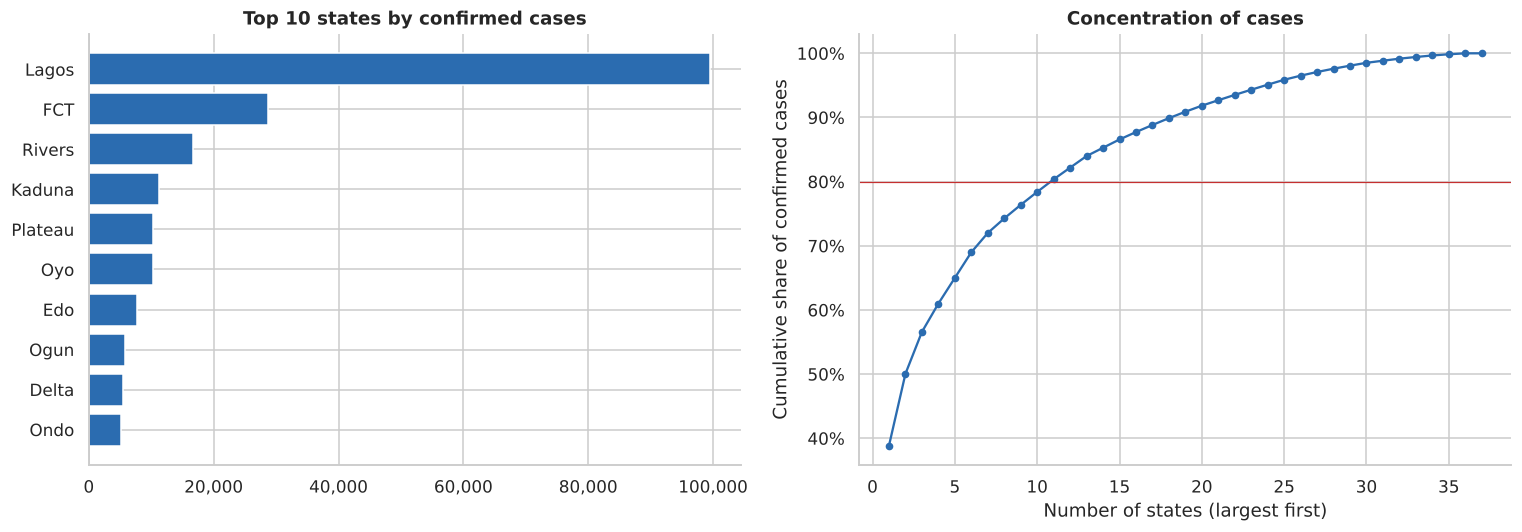

Lagos alone accounts for 38.9% of confirmed cases; the top 5 states for 65.0%; the top 10 for 78.4%.
11 of 37 states account for 80% of all confirmed cases.


In [5]:
ranked = df.sort_values("Confirmed", ascending=False).reset_index(drop=True)
ranked["Share"] = ranked["Confirmed"] / ranked["Confirmed"].sum()
ranked["Cumulative share"] = ranked["Share"].cumsum()

top10 = ranked.head(10)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(top10["State"][::-1], top10["Confirmed"][::-1], color=BLUE)
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[0].set_title("Top 10 states by confirmed cases")

axes[1].plot(np.arange(1, len(ranked) + 1), ranked["Cumulative share"], marker="o", ms=4, color=BLUE)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[1].set_xlabel("Number of states (largest first)")
axes[1].set_ylabel("Cumulative share of confirmed cases")
axes[1].set_title("Concentration of cases")
axes[1].axhline(0.8, color=RED, lw=0.8)
plt.tight_layout()
plt.show()

n80 = int((ranked["Cumulative share"] < 0.8).sum()) + 1
print(f"{ranked.loc[0, 'State']} alone accounts for {ranked.loc[0, 'Share']:.1%} of confirmed cases; "
      f"the top 5 states for {ranked.loc[4, 'Cumulative share']:.1%}; the top 10 for {ranked.loc[9, 'Cumulative share']:.1%}.")
print(f"{n80} of {len(ranked)} states account for 80% of all confirmed cases.")

## 5. Fatality rate by state, with uncertainty

A raw death rate misleads when the case count is small: a state with 5 confirmed cases and 2 deaths shows 40%, which is just
noise. Two safeguards are used:

1. Only states with at least `MIN_CASES` confirmed cases are interpreted.
2. Each rate carries a 95% **Wilson confidence interval**. A state is flagged only if its interval lies entirely above or below the
   national rate.

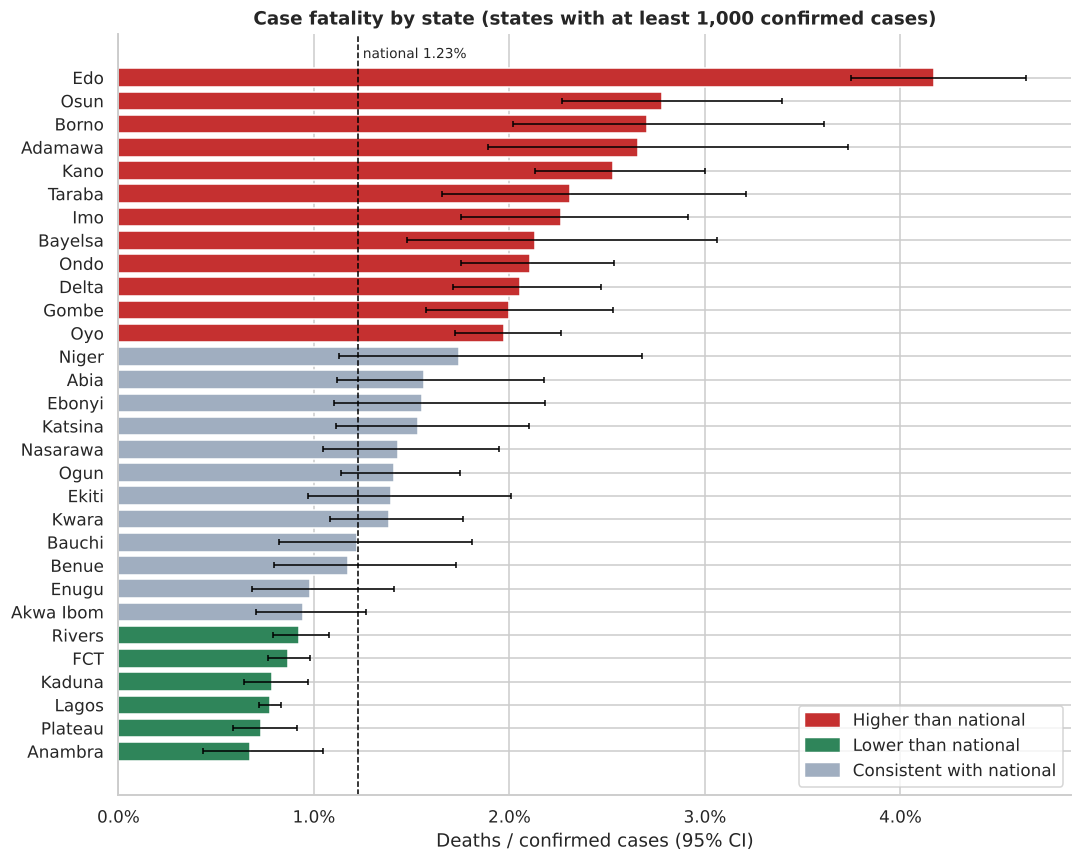

30 states have at least 1,000 cases; 7 smaller states are excluded from rate comparisons (together 1.5% of all cases).


,State,Confirmed,Deaths,CFR,Low,High,Flag
0,Edo,7694,321,4.17%,3.75%,4.64%,Higher than national
1,Osun,3311,92,2.78%,2.27%,3.40%,Higher than national
2,Borno,1629,44,2.70%,2.02%,3.61%,Higher than national
3,Adamawa,1203,32,2.66%,1.89%,3.73%,Higher than national
4,Kano,5020,127,2.53%,2.13%,3.00%,Higher than national
5,Taraba,1473,34,2.31%,1.66%,3.21%,Higher than national
6,Imo,2563,58,2.26%,1.75%,2.91%,Higher than national
7,Bayelsa,1315,28,2.13%,1.48%,3.06%,Higher than national
8,Ondo,5173,109,2.11%,1.75%,2.54%,Higher than national
9,Delta,5403,111,2.05%,1.71%,2.47%,Higher than national


In [6]:
small = df[df["Confirmed"] < MIN_CASES].copy()
big = df[df["Confirmed"] >= MIN_CASES].copy()
big["CFR"] = big["Deaths"] / big["Confirmed"]
bounds = big.apply(lambda r: wilson(r["Deaths"], r["Confirmed"]), axis=1)
big["Low"] = [b[0] for b in bounds]
big["High"] = [b[1] for b in bounds]
big["Flag"] = np.where(big["Low"] > nat_cfr, "Higher than national",
                np.where(big["High"] < nat_cfr, "Lower than national", "Consistent with national"))
big = big.sort_values("CFR")

palette = {"Higher than national": RED, "Lower than national": GREEN, "Consistent with national": GREY}
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(big["State"], big["CFR"], color=big["Flag"].map(palette))
ax.errorbar(big["CFR"], big["State"], xerr=[big["CFR"] - big["Low"], big["High"] - big["CFR"]],
            fmt="none", ecolor="black", elinewidth=1, capsize=2)
ax.axvline(nat_cfr, color="black", ls="--", lw=1)
ax.text(nat_cfr, len(big) - 0.3, f" national {nat_cfr:.2%}", va="bottom", fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))
ax.set_xlabel("Deaths / confirmed cases (95% CI)")
ax.set_title(f"Case fatality by state (states with at least {MIN_CASES:,} confirmed cases)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()]
ax.legend(handles, palette.keys(), loc="lower right")
plt.tight_layout()
plt.show()

print(f"{len(big)} states have at least {MIN_CASES:,} cases; {len(small)} smaller states are excluded from rate comparisons "
      f"(together {small['Confirmed'].sum() / df['Confirmed'].sum():.1%} of all cases).")
flagged = big[big["Flag"] != "Consistent with national"].sort_values("CFR", ascending=False)
flagged[["State", "Confirmed", "Deaths", "CFR", "Low", "High", "Flag"]].assign(
    CFR=lambda d: d["CFR"].map("{:.2%}".format), Low=lambda d: d["Low"].map("{:.2%}".format),
    High=lambda d: d["High"].map("{:.2%}".format)).reset_index(drop=True)

### Why small states are excluded

The five states with the smallest case counts show how unstable raw rates are:

In [7]:
tiny = df.nsmallest(5, "Confirmed").copy()
tiny["Death rate"] = (tiny["Deaths"] / tiny["Confirmed"]).map("{:.1%}".format)
lows, highs = zip(*[wilson(d, c) for d, c in zip(tiny["Deaths"], tiny["Confirmed"])])
tiny["95% CI"] = [f"{l:.1%} to {h:.1%}" for l, h in zip(lows, highs)]
tiny[["State", "Confirmed", "Deaths", "Death rate", "95% CI"]].reset_index(drop=True)

,State,Confirmed,Deaths,Death rate,95% CI
0,Kogi,5,2,40.0%,11.8% to 76.9%
1,Zamfara,375,9,2.4%,1.3% to 4.5%
2,Kebbi,480,16,3.3%,2.1% to 5.3%
3,Yobe,609,9,1.5%,0.8% to 2.8%
4,Jigawa,669,18,2.7%,1.7% to 4.2%


## 6. Volume versus severity

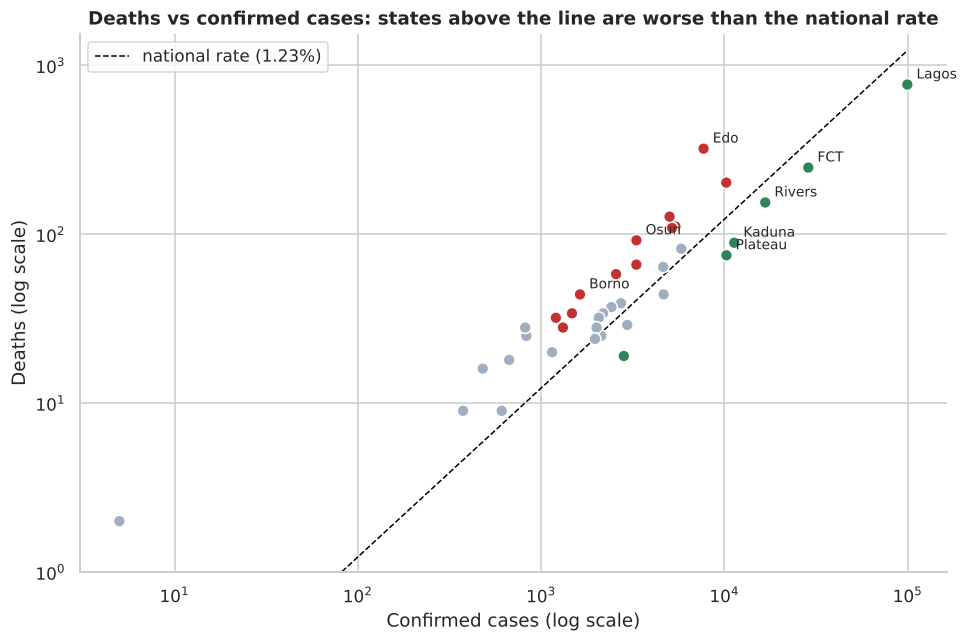

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))
colors = df["State"].map(big.set_index("State")["Flag"]).map(palette).fillna(GREY)
ax.scatter(df["Confirmed"], df["Deaths"], s=60, c=colors, edgecolor="white", zorder=3)
ax.set_xscale("log")
ax.set_yscale("log")
xs = np.array([df["Confirmed"].min(), df["Confirmed"].max()])
ax.plot(xs, xs * nat_cfr, color="black", ls="--", lw=1, label=f"national rate ({nat_cfr:.2%})")
label_states = set(ranked.head(5)["State"]) | set(big.nlargest(3, "CFR")["State"])   # keep labels readable
for _, r in df[df["State"].isin(label_states)].iterrows():
    ax.annotate(r["State"], (r["Confirmed"], r["Deaths"]), textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.set_ylim(1, df["Deaths"].max() * 2)
ax.set_xlabel("Confirmed cases (log scale)")
ax.set_ylabel("Deaths (log scale)")
ax.set_title("Deaths vs confirmed cases: states above the line are worse than the national rate")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Where are active cases concentrated?

A high *active* share means many cases not yet resolved, which points to a recent rise (or to slow reporting of recoveries).

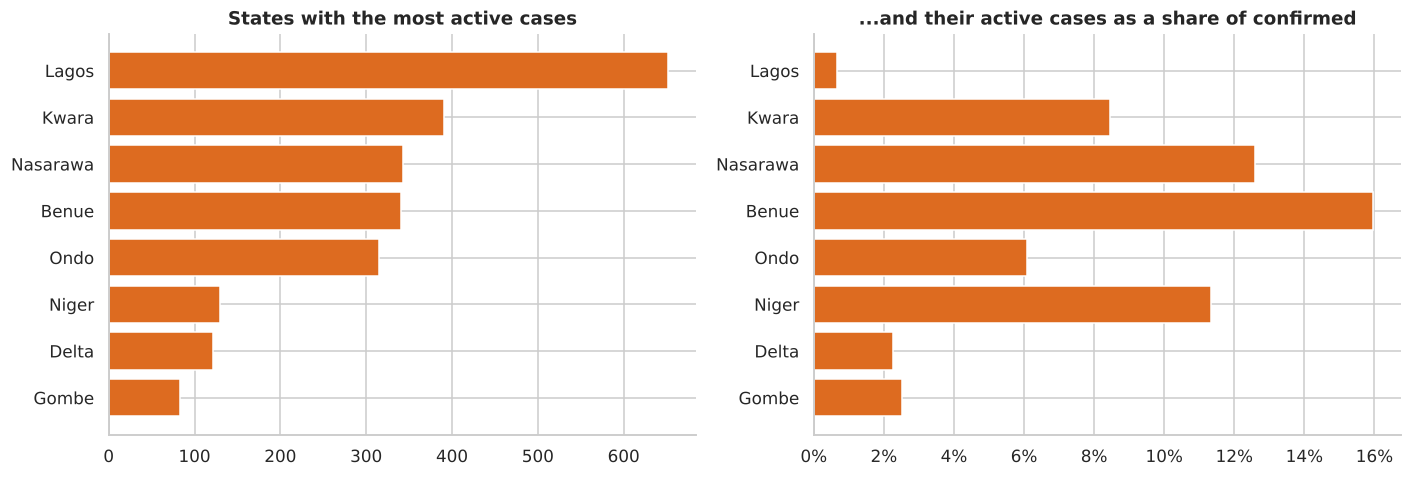

The 8 states with the most active cases hold 83% of the 2,849 active cases nationally.


In [9]:
big["Active share"] = big["Active"] / big["Confirmed"]
act = big.sort_values("Active", ascending=False).head(8)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh(act["State"][::-1], act["Active"][::-1], color=ORANGE)
axes[0].set_title("States with the most active cases")
axes[1].barh(act["State"][::-1], act["Active share"][::-1], color=ORANGE)
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[1].set_title("...and their active cases as a share of confirmed")
plt.tight_layout()
plt.show()

print(f"The {len(act)} states with the most active cases hold {act['Active'].sum() / nat['Active']:.0%} of the {nat['Active']:,} active cases nationally.")

## 8. Key findings (computed from the data above)

In [10]:
hi_states = flagged[flagged["Flag"] == "Higher than national"]["State"].tolist()
lo_states = flagged[flagged["Flag"] == "Lower than national"]["State"].tolist()
top_active = act.iloc[0]
top_share = big.sort_values("Active share", ascending=False).iloc[0]

print(f"1. Scale: {nat['Confirmed']:,} confirmed cases and {nat['Deaths']:,} deaths across {len(df)} states/FCT; "
      f"recovery rate {nat['Discharged'] / nat['Confirmed']:.1%}, death rate {nat_cfr:.2%}.")
print(f"2. Concentration: {ranked.loc[0, 'State']} holds {ranked.loc[0, 'Share']:.0%} of cases and the top 5 states "
      f"{ranked.loc[4, 'Cumulative share']:.0%}; {n80} states make up 80% of the national total.")
print(f"3. Severity: after accounting for sample size, {len(hi_states)} states have a death rate significantly above the national rate "
      f"({', '.join(hi_states) if hi_states else 'none'}) and {len(lo_states)} significantly below ({', '.join(lo_states) if lo_states else 'none'}).")
print(f"4. Volume is not severity: {ranked.loc[0, 'State']} has the most deaths ({int(ranked.sort_values('Deaths', ascending=False).iloc[0]['Deaths']):,}) "
      f"but a death rate of {big.set_index('State').loc[ranked.loc[0, 'State'], 'CFR']:.2%}, versus {nat_cfr:.2%} nationally.")
print(f"5. Open cases: {top_active['State']} has the most active cases ({int(top_active['Active']):,}); "
      f"{top_share['State']} has the highest active share ({top_share['Active share']:.1%} of its confirmed cases).")

1. Scale: 256,028 confirmed cases and 3,143 deaths across 37 states/FCT; recovery rate 97.7%, death rate 1.23%.
2. Concentration: Lagos holds 39% of cases and the top 5 states 65%; 11 states make up 80% of the national total.
3. Severity: after accounting for sample size, 12 states have a death rate significantly above the national rate (Edo, Osun, Borno, Adamawa, Kano, Taraba, Imo, Bayelsa, Ondo, Delta, Gombe, Oyo) and 6 significantly below (Rivers, FCT, Kaduna, Lagos, Plateau, Anambra).
4. Volume is not severity: Lagos has the most deaths (769) but a death rate of 0.77%, versus 1.23% nationally.
5. Open cases: Lagos has the most active cases (652); Benue has the highest active share (16.0% of its confirmed cases).


## 9. Caveats

- **Single snapshot.** There is no time dimension, so trends, waves and growth rates cannot be assessed.
- **No population data.** Counts are not per-capita, so large states naturally dominate; a per-100,000 view needs population figures.
- **Reporting differences.** Testing intensity and death-registration quality differ widely by state, so a low death rate can mean
  under-reporting as well as better outcomes.
- **Confidence intervals** reflect sampling variation only, not data-quality bias.
- The data comes from the dashboard's embedded NCDC snapshot; it was not re-verified against the source.